In [1]:
import sys
print(sys.executable)
import pandas, seaborn
print("OK")

c:\Users\OK\Downloads\football-match-prediction\.venv\Scripts\python.exe
OK


In [2]:
import sys
sys.path.append("../src")

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from config import PROCESSED_DIR, FIGURES_DIR

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

df = pd.read_csv(PROCESSED_DIR / "matches_clean.csv",
                 parse_dates=["date"], dtype={"season": str})
df["season_label"] = "20" + df["season"].str[:2] + "-" + df["season"].str[2:]
df["total_goals"] = df["home_goals"] + df["away_goals"]
df.head()

,date,home_team,away_team,home_goals,away_goals,result,league,season,home_shots,away_shots,home_shots_on_target,away_shots_on_target,home_corners,away_corners,home_fouls,away_fouls,season_label,total_goals
0,2015-07-24,St Truiden,Club Brugge,2.0,1.0,H,Pro League,1516,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2015-16,3.0
1,2015-07-25,Genk,Oud-Heverlee Leuven,3.0,1.0,H,Pro League,1516,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2015-16,4.0
2,2015-07-25,Kortrijk,Standard,2.0,1.0,H,Pro League,1516,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2015-16,3.0
3,2015-07-25,Oostende,Mechelen,3.0,1.0,H,Pro League,1516,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2015-16,4.0
4,2015-07-25,Waregem,Lokeren,3.0,1.0,H,Pro League,1516,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2015-16,4.0


In [3]:
print(df.shape)
df.info()
df.describe().round(2)

(26791, 18)
<class 'pandas.DataFrame'>
RangeIndex: 26791 entries, 0 to 26790
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   date                  26791 non-null  datetime64[us]
 1   home_team             26791 non-null  str           
 2   away_team             26791 non-null  str           
 3   home_goals            26791 non-null  float64       
 4   away_goals            26791 non-null  float64       
 5   result                26791 non-null  str           
 6   league                26791 non-null  str           
 7   season                26791 non-null  str           
 8   home_shots            25079 non-null  float64       
 9   away_shots            25079 non-null  float64       
 10  home_shots_on_target  25079 non-null  float64       
 11  away_shots_on_target  25079 non-null  float64       
 12  home_corners          25079 non-null  float64       
 13  away_corners   

,date,home_goals,away_goals,home_shots,away_shots,home_shots_on_target,away_shots_on_target,home_corners,away_corners,home_fouls,away_fouls,total_goals
count,26791,26791.00,26791.00,25079.00,25079.00,25079.00,25079.00,25079.00,25079.00,24599.00,24599.00,26791.00
mean,2020-07-10 07:40:02.463513,1.56,1.25,13.50,11.10,4.88,4.03,5.46,4.47,12.36,12.63,2.80
min,2015-07-24 00:00:00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,2017-12-26 00:00:00,1.00,0.00,10.00,8.00,3.00,2.00,3.00,3.00,9.00,10.00,2.00
50%,2020-09-26 00:00:00,1.00,1.00,13.00,11.00,5.00,4.00,5.00,4.00,12.00,12.00,3.00
75%,2023-01-23 00:00:00,2.00,2.00,17.00,14.00,6.00,5.00,7.00,6.00,15.00,15.00,4.00
max,2025-05-25 00:00:00,10.00,13.00,46.00,45.00,20.00,23.00,26.00,19.00,33.00,34.00,13.00
std,NaN,1.32,1.18,5.37,4.78,2.63,2.38,2.98,2.65,4.16,4.18,1.68


In [4]:
counts = df.pivot_table(index="league", columns="season_label",
                        values="date", aggfunc="count")
counts

season_label,2015-16,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25
league,,,,,,,,,,
Bundesliga,306,306,306,306,306,306,306,306,306,306
Eredivisie,306,306,306,306,232,306,306,306,306,306
La Liga,380,380,380,380,380,380,380,380,380,380
Ligue 1,380,380,380,380,279,380,380,380,306,306
Premier League,380,380,380,380,380,380,380,380,380,380
Primeira Liga,306,306,306,306,306,306,306,306,306,306
Pro League,240,240,240,240,232,306,306,306,312,312
Serie A,380,380,380,380,380,380,380,380,380,380


result
H    44.3
D    24.7
A    31.0
Name: proportion, dtype: float64


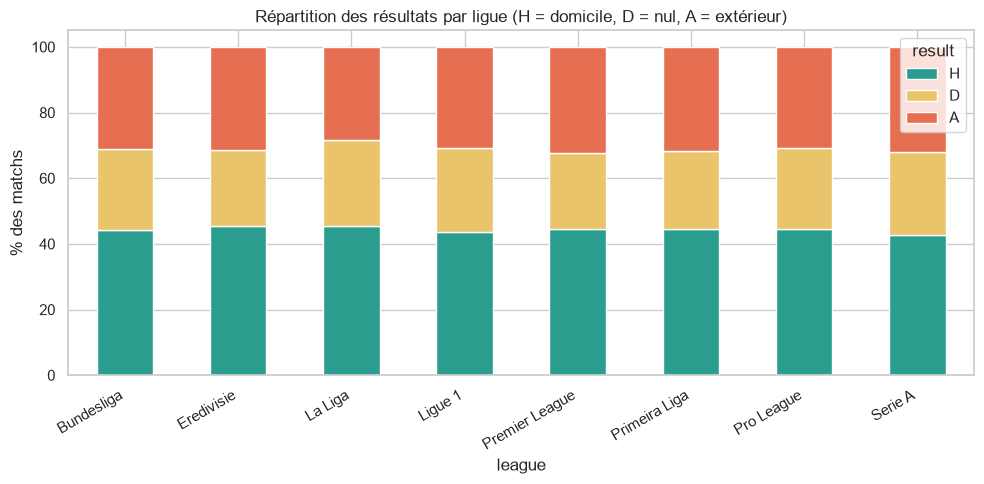

In [5]:
order = ["H", "D", "A"]
overall = df["result"].value_counts(normalize=True).reindex(order) * 100
print(overall.round(1))

by_league = (df.groupby("league")["result"].value_counts(normalize=True)
               .unstack().reindex(columns=order) * 100)

ax = by_league.plot(kind="bar", stacked=True, figsize=(10, 5),
                    color=["#2a9d8f", "#e9c46a", "#e76f51"])
ax.set_ylabel("% des matchs")
ax.set_title("Répartition des résultats par ligue (H = domicile, D = nul, A = extérieur)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "results_by_league.png", dpi=150)
plt.show()

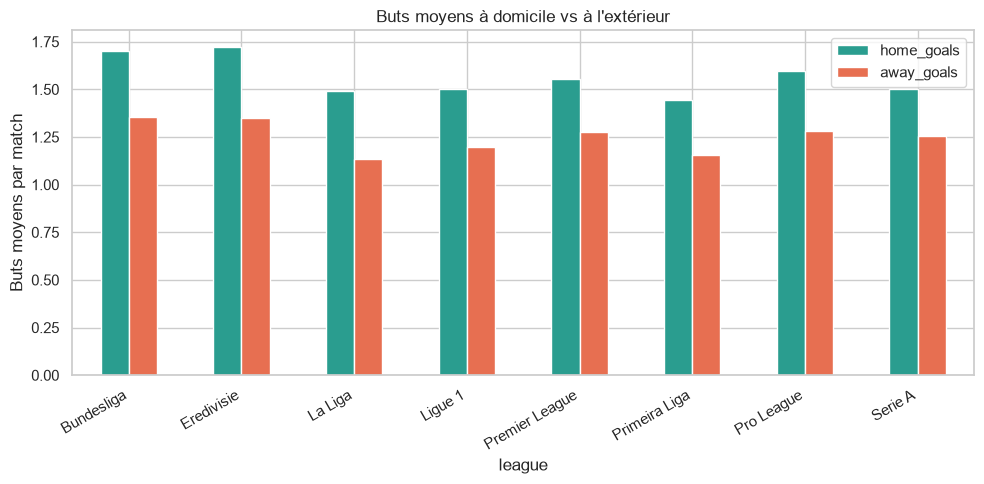

In [6]:
goals = df.groupby("league")[["home_goals", "away_goals"]].mean()
ax = goals.plot(kind="bar", figsize=(10, 5), color=["#2a9d8f", "#e76f51"])
ax.set_ylabel("Buts moyens par match")
ax.set_title("Buts moyens à domicile vs à l'extérieur")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "home_advantage_goals.png", dpi=150)
plt.show()

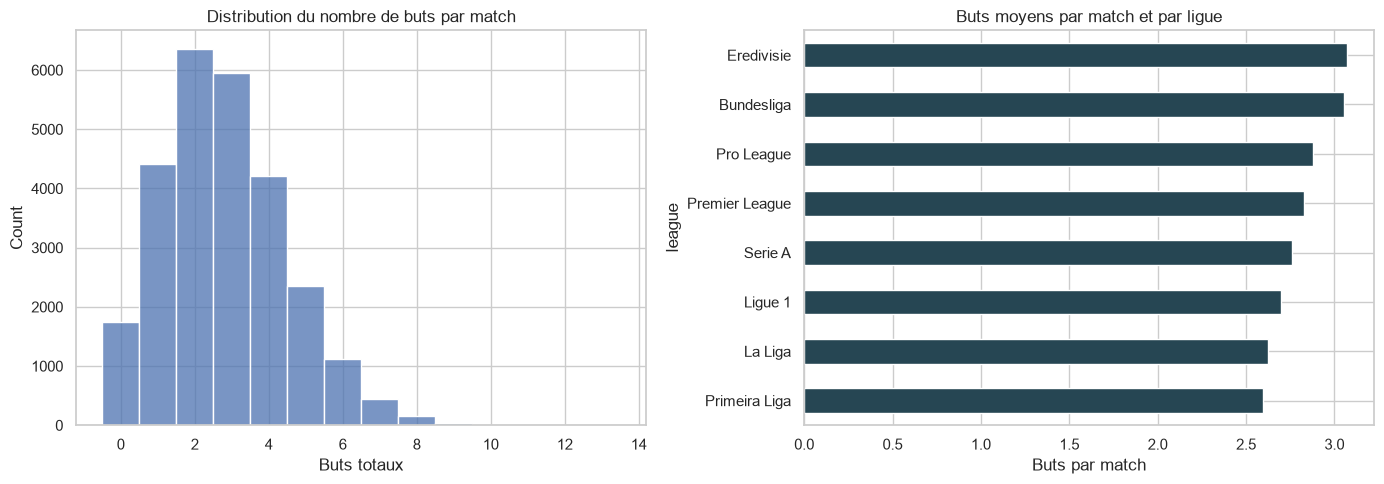

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["total_goals"], bins=range(0, 11), discrete=True, ax=axes[0])
axes[0].set_title("Distribution du nombre de buts par match")
axes[0].set_xlabel("Buts totaux")

avg = df.groupby("league")["total_goals"].mean().sort_values()
avg.plot(kind="barh", ax=axes[1], color="#264653")
axes[1].set_title("Buts moyens par match et par ligue")
axes[1].set_xlabel("Buts par match")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "goals_per_match.png", dpi=150)
plt.show()

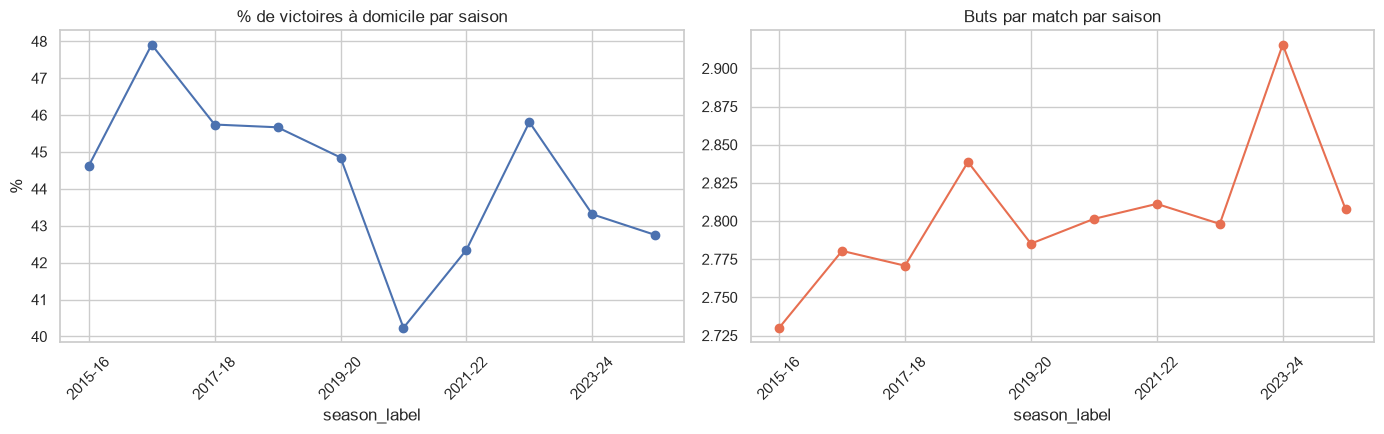

In [8]:
season_stats = df.groupby("season_label").agg(
    home_win_pct=("result", lambda s: (s == "H").mean() * 100),
    goals_per_match=("total_goals", "mean"),
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
season_stats["home_win_pct"].plot(marker="o", ax=axes[0])
axes[0].set_title("% de victoires à domicile par saison")
axes[0].set_ylabel("%")

season_stats["goals_per_match"].plot(marker="o", color="#e76f51", ax=axes[1])
axes[1].set_title("Buts par match par saison")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "evolution_by_season.png", dpi=150)
plt.show()

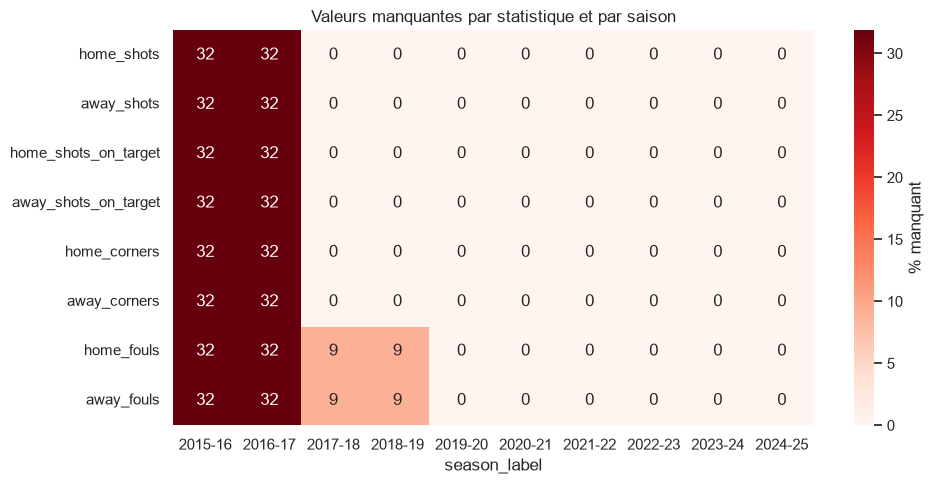

In [9]:
stat_cols = [c for c in ["home_shots", "away_shots", "home_shots_on_target",
                         "away_shots_on_target", "home_corners", "away_corners",
                         "home_fouls", "away_fouls"] if c in df.columns]

missing = df.groupby("season_label")[stat_cols].apply(lambda g: g.isna().mean() * 100)

plt.figure(figsize=(10, 5))
sns.heatmap(missing.T, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% manquant"})
plt.title("Valeurs manquantes par statistique et par saison")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "missing_values.png", dpi=150)
plt.show()

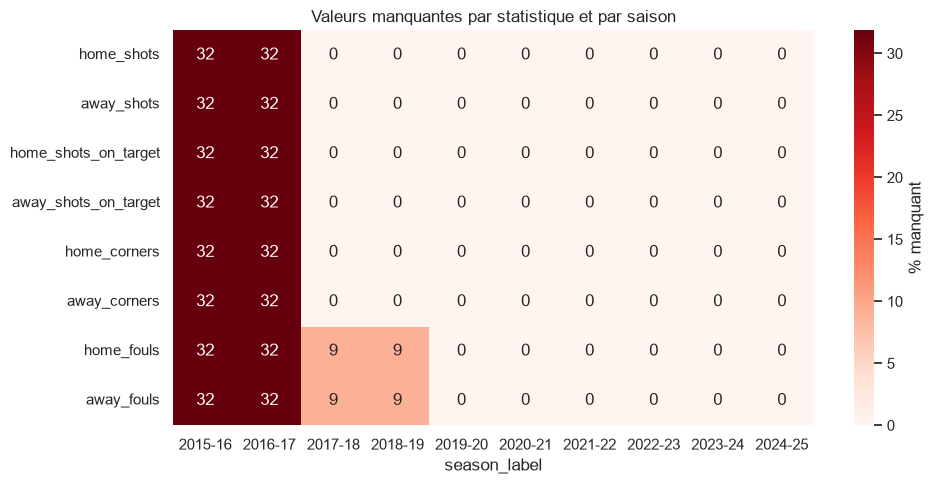

In [10]:
stat_cols = [c for c in ["home_shots", "away_shots", "home_shots_on_target",
                         "away_shots_on_target", "home_corners", "away_corners",
                         "home_fouls", "away_fouls"] if c in df.columns]

missing = df.groupby("season_label")[stat_cols].apply(lambda g: g.isna().mean() * 100)

plt.figure(figsize=(10, 5))
sns.heatmap(missing.T, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% manquant"})
plt.title("Valeurs manquantes par statistique et par saison")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "missing_values.png", dpi=150)
plt.show()

In [11]:
from IPython.display import Markdown, display

# --- Calculs ---
n = len(df)
pct = df["result"].value_counts(normalize=True) * 100
h, d, a = pct.get("H", 0), pct.get("D", 0), pct.get("A", 0)

hg, ag = df["home_goals"].mean(), df["away_goals"].mean()
tg = df["total_goals"].mean()

home_win_league = (df.groupby("league")["result"]
                     .apply(lambda s: (s == "H").mean() * 100).sort_values())
low_l, low_v = home_win_league.index[0], home_win_league.iloc[0]
high_l, high_v = home_win_league.index[-1], home_win_league.iloc[-1]

goals_league = df.groupby("league")["total_goals"].mean().sort_values()
gl_l, gl_v = goals_league.index[0], goals_league.iloc[0]
gh_l, gh_v = goals_league.index[-1], goals_league.iloc[-1]

draw_league = (df.groupby("league")["result"]
                 .apply(lambda s: (s == "D").mean() * 100).sort_values())
dl_l, dl_v = draw_league.index[0], draw_league.iloc[0]
dh_l, dh_v = draw_league.index[-1], draw_league.iloc[-1]

season_home = (df.groupby("season_label")["result"]
                 .apply(lambda s: (s == "H").mean() * 100))
pre = season_home[[s for s in ["2015-2016", "2016-2017", "2017-2018", "2018-2019"]
                   if s in season_home.index]]
if "2020-2021" in season_home.index and len(pre) > 0:
    covid = season_home["2020-2021"]
    covid_txt = (f"en 2020-2021 (stades vides), les victoires à domicile tombent à "
                 f"**{covid:.1f} %**, contre **{pre.mean():.1f} %** en moyenne sur "
                 f"2015-2016 à 2018-2019 ({covid - pre.mean():+.1f} points).")
else:
    covid_txt = "la saison 2020-2021 n'est pas disponible dans les données."

if "home_shots" in df.columns:
    avail = (df.groupby("season_label")["home_shots"]
               .apply(lambda s: s.notna().mean() * 100))
    ok = avail[avail >= 90]
    stats_txt = (f"les tirs sont renseignés à plus de 90 % pour **{len(ok)} saison(s) sur "
                 f"{len(avail)}** (taux global de valeurs présentes : "
                 f"{df['home_shots'].notna().mean() * 100:.0f} %).")
else:
    stats_txt = "les tirs, corners et fautes ne sont pas présents dans le jeu de données."

# --- Rédaction ---
texte = f"""## Conclusions de l'analyse exploratoire

Le jeu de données contient **{n} matchs** issus de **{df['league'].nunique()} championnats** et **{df['season'].nunique()} saisons**.

- **Répartition des résultats** : {h:.1f} % de victoires à domicile, {d:.1f} % de nuls et {a:.1f} % de victoires à l'extérieur. Le modèle de référence (toujours prédire « victoire à domicile ») atteint donc environ **{h:.1f} %** d'accuracy.
- **Avantage du terrain** : les équipes à domicile marquent en moyenne **{hg:.2f} buts** contre **{ag:.2f}** à l'extérieur. La part de victoires à domicile est la plus élevée en **{high_l}** ({high_v:.1f} %) et la plus faible en **{low_l}** ({low_v:.1f} %).
- **Évolution dans le temps** : {covid_txt}
- **Buts** : la moyenne est de **{tg:.2f} buts par match**, du plus défensif (**{gl_l}**, {gl_v:.2f}) au plus offensif (**{gh_l}**, {gh_v:.2f}).
- **Nuls** : la part de matchs nuls va de {dl_v:.1f} % en **{dl_l}** à {dh_v:.1f} % en **{dh_l}**. Cette classe, la moins nette statistiquement, sera la plus difficile à prédire.
- **Données disponibles** : {stats_txt} Les premières variables seront donc construites à partir des buts et des résultats, disponibles sur toute la période.
- **Implication pour la modélisation** : le modèle devra dépasser la référence d'environ {h:.0f} % d'accuracy, en gardant un oeil sur la log-loss et sur le F1 de la classe « nul », plutôt que sur l'accuracy seule.
"""

display(Markdown(texte))

from config import ROOT
(ROOT / "reports" / "eda_conclusions.md").write_text(texte, encoding="utf-8")

## Conclusions de l'analyse exploratoire

Le jeu de données contient **26791 matchs** issus de **8 championnats** et **10 saisons**.

- **Répartition des résultats** : 44.3 % de victoires à domicile, 24.7 % de nuls et 31.0 % de victoires à l'extérieur. Le modèle de référence (toujours prédire « victoire à domicile ») atteint donc environ **44.3 %** d'accuracy.
- **Avantage du terrain** : les équipes à domicile marquent en moyenne **1.56 buts** contre **1.25** à l'extérieur. La part de victoires à domicile est la plus élevée en **La Liga** (45.4 %) et la plus faible en **Serie A** (42.7 %).
- **Évolution dans le temps** : la saison 2020-2021 n'est pas disponible dans les données.
- **Buts** : la moyenne est de **2.80 buts par match**, du plus défensif (**Primeira Liga**, 2.60) au plus offensif (**Eredivisie**, 3.07).
- **Nuls** : la part de matchs nuls va de 23.3 % en **Premier League** à 26.2 % en **La Liga**. Cette classe, la moins nette statistiquement, sera la plus difficile à prédire.
- **Données disponibles** : les tirs sont renseignés à plus de 90 % pour **8 saison(s) sur 10** (taux global de valeurs présentes : 94 %). Les premières variables seront donc construites à partir des buts et des résultats, disponibles sur toute la période.
- **Implication pour la modélisation** : le modèle devra dépasser la référence d'environ 44 % d'accuracy, en gardant un oeil sur la log-loss et sur le F1 de la classe « nul », plutôt que sur l'accuracy seule.


1470